# Disneyland reviews: exploration, sentiment and frequent itemsets
### Data checks → BoW / TF-IDF → complaint categories → FIM and association rules

This beginner-friendly workbook now covers the three original tasks **plus frequent itemset mining (FIM)** and branch comparisons. It uses your hosted dataset path `/mnt/data/public/disneyland-reviews/DisneylandReviews.csv`, with an explicit local-file fallback for running beside the CSV on your computer.

Run cells from top to bottom (Shift+Enter) in Jupyter, VS Code or your hosted notebook environment. Start with Section 0. The sentiment step can take several minutes. Saved outputs are from validation on the local CSV; rerun to obtain results for your hosted copy.

1. Check columns, missing data, duplicates, ratings and coverage.
2. Clean text and explore BoW and TF-IDF.
3. Extract attraction/service mentions, complaint candidates and sentiment.
4. Build one complaint basket per usable review; run Apriori and association rules.
5. Compare the same patterns across branches and export the results.

The information-retrieval notebooks supply the CountVectorizer teaching sequence; lecture slides 15–17 supply BoW/TF-IDF concepts. The supplied **Frequent Itemset Mining (3).ipynb**, prepared by Christian Alis, supplies the set-based transaction representation, Apriori approach and single-consequent association-rule convention. This workbook adapts those concepts to complaint categories. Its labels are automatically detected candidates pending human validation; patterns describe co-mentions, not causes or visitor-level probabilities.


## 0. Setup (start here)
Run the installation cell once if your kernel does not already have these packages. Uncomment the line by removing `#`. Restart the kernel after installation, then run the notebook from the imports cell. `%pip` installs into the active notebook environment; it needs internet the first time.

`pandas` works with tables, `numpy` with numbers, `matplotlib` with charts, `scikit-learn` with word vectors, and `vaderSentiment` with a small English sentiment dictionary. VADER includes its dictionary; no separate NLTK download is required.

In [1]:
# %pip install pandas numpy matplotlib scikit-learn vaderSentiment

In [2]:
from pathlib import Path
import re
import html
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, ENGLISH_STOP_WORDS
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
RANDOM_SEED = 42
# Your shared / hosted dataset location is the first choice.
folder = Path("/mnt/data/public/disneyland-reviews")
DATA_PATH = folder / "DisneylandReviews.csv"
if DATA_PATH.exists():
    print("Contents of the folder:")
    for item in sorted(folder.iterdir()):
        print(item.name)
elif Path("DisneylandReviews.csv").exists():
    # Explicit fallback for local Windows/Jupyter use; never silently choose another dataset.
    DATA_PATH = Path("DisneylandReviews.csv")
    print("Hosted path unavailable; using the local DisneylandReviews.csv instead.")
print("Selected CSV:", DATA_PATH.resolve())
OUTPUT_DIR = Path("outputs/disneyland_analysis")
print("Working folder:", Path.cwd())

Hosted path unavailable; using the local DisneylandReviews.csv instead.
Selected CSV: C:\Users\jlgel\Downloads\BDCC-Lab1-\DisneylandReviews.csv
Working folder: C:\Users\jlgel\Downloads\BDCC-Lab1-


## 1. Load the data and understand each column
Each row is a **review record**, not necessarily a distinct visitor. `Review_ID` identifies a review, not a person. `Branch` is the reviewed park; `Reviewer_Location` is the reviewer's stated location, not the attraction's location or confirmed nationality.

| Column | Meaning / check |
|---|---|
| Review_ID | Review identifier; inspect duplicates before assuming uniqueness |
| Rating | Overall rating, expected integer 1–5 |
| Year_Month | Review month; the literal word `missing` must be handled |
| Reviewer_Location | Stated reviewer location; coverage can be uneven |
| Review_Text | Original narrative; keep this for checking the results |
| Branch | Park branch; use this when comparing coverage |

We use `encoding="latin-1"`, matching your supplied loading code. This accepts all byte values, so successful loading alone does not prove that every accented character is decoded as intended. Inspect sample text if you see unusual characters.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH}. Check the hosted mount or edit DATA_PATH.")

encoding_used = "latin-1"
raw = pd.read_csv(DATA_PATH, encoding=encoding_used, dtype={"Review_ID": "string"})
required = ["Review_ID", "Rating", "Year_Month", "Reviewer_Location", "Review_Text", "Branch"]
missing_columns = set(required) - set(raw.columns)
if missing_columns:
    raise ValueError(f"Required columns not found: {missing_columns}")
print(f"Loaded {len(raw):,} rows and {raw.shape[1]} columns using {encoding_used}.")
display(raw.head(3))
raw.info()

Loaded 42,656 rows and 6 columns using latin-1.
<class 'pandas.DataFrame'>
RangeIndex: 42656 entries, 0 to 42655
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Review_ID          42656 non-null  string
 1   Rating             42656 non-null  int64 
 2   Year_Month         42656 non-null  str   
 3   Reviewer_Location  42656 non-null  str   
 4   Review_Text        42656 non-null  str   
 5   Branch             42656 non-null  str   
dtypes: int64(1), str(4), string(1)
memory usage: 2.0 MB


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very similar in the layout whe...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only stay in Tomorrowland ....",Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid when I was visiting the park otherwise it would be a big iss...,Disneyland_HongKong


### 1.1 Missing values, including hidden missing values
`isna()` finds true missing values. It does not automatically recognize every placeholder such as `missing`, `unknown`, or a blank space. We show both types before changing anything. The placeholder list is a documented assumption: adjust it if your data uses a word legitimately.

In [4]:
PLACEHOLDERS = {"", "missing", "unknown", "n/a", "na", "null", "none"}
audit_rows = []
for column in raw.columns:
    text = raw[column].astype("string").str.strip().str.lower()
    placeholder = text.isin(PLACEHOLDERS)
    total_missing = raw[column].isna() | placeholder
    audit_rows.append({"column": column, "dtype": str(raw[column].dtype),
                       "actual_nulls": int(raw[column].isna().sum()),
                       "placeholders": int(placeholder.sum()),
                       "missing_total": int(total_missing.sum()),
                       "missing_pct": round(100 * total_missing.mean(), 2)})
missing_summary = pd.DataFrame(audit_rows)
display(missing_summary)

,column,dtype,actual_nulls,placeholders,missing_total,missing_pct
0,Review_ID,string,0,0,0,0.00
1,Rating,int64,0,0,0,0.00
2,Year_Month,str,0,2613,2613,6.13
3,Reviewer_Location,str,0,0,0,0.00
4,Review_Text,str,0,0,0,0.00
5,Branch,str,0,0,0,0.00


### 1.2 Duplicate policy and working table
Remove only **exact duplicate rows**. Keep rows with a repeated ID but different content, and display them for inspection. We use a separate `row_id` tied to the original CSV row position so every extracted result can be traced back. Duplicate IDs are not automatically duplicate people.

Dates and invalid ratings become missing; they do not cause the whole review to be dropped. Missing branch/location gets an explicit label. No rating is imputed.

In [5]:
exact_duplicates = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()
df.insert(0, "row_id", df.index)  # Original zero-based CSV data-row position.
df = df.reset_index(drop=True)

for column in required:
    if column != "Rating":
        df[column] = df[column].astype("string").str.strip()
        df.loc[df[column].str.lower().isin(PLACEHOLDERS), column] = pd.NA

rating_numeric = pd.to_numeric(df["Rating"], errors="coerce")
invalid_rating = rating_numeric.notna() & ~rating_numeric.isin([1, 2, 3, 4, 5])
df["rating"] = rating_numeric.where(rating_numeric.isin([1, 2, 3, 4, 5]))
df["review_month"] = pd.to_datetime(df["Year_Month"], format="%Y-%m", errors="coerce")
for column in ["Branch", "Reviewer_Location"]:
    df[column] = df[column].fillna("Unknown")
df["has_text"] = df["Review_Text"].fillna("").str.strip().ne("")

repeated_ids = df.loc[df["Review_ID"].notna() & df["Review_ID"].duplicated(keep=False)]
print("Exact duplicate rows removed:", exact_duplicates)
print("Retained review records:", len(df))
print("Rows with repeated non-missing IDs after exact deduplication:", len(repeated_ids))
print("Invalid non-missing numeric ratings:", int(invalid_rating.sum()))
print("Missing/unparseable ratings:", int(df["rating"].isna().sum()))
print("Missing/unparseable dates:", int(df["review_month"].isna().sum()))
print("Rows without usable original text:", int((~df["has_text"]).sum()))
display(repeated_ids[required].head(8))

Exact duplicate rows removed: 12
Retained review records: 42644
Rows with repeated non-missing IDs after exact deduplication: 16
Invalid non-missing numeric ratings: 0
Missing/unparseable ratings: 0
Missing/unparseable dates: 2613
Rows without usable original text: 0


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
7858,168489234,4,2013-1,Malaysia,"Reading reviews here, I was really skeptical almost not in our itinerary.Yes, we encountered some people...",Disneyland_HongKong
7867,168489234,4,2013-1,Malaysia,"Reading reviews here, I was really skeptical almost not in our itinerary. Yes, we encountered some peop...",Disneyland_HongKong
7940,164830205,3,2012-7,United States,"If you've visited DisneyWorld in Orlando, your most enduring impression of HK Disney will be small. Cind...",Disneyland_HongKong
7949,164830205,3,2012-7,United States,"If you've visited DisneyWorld in Orlando, your most enduring impression of HK Disney will be small. Cin...",Disneyland_HongKong
9168,121615246,4,2011-12,India,I visited Hong Kong Disneyland with my family ( wife and daughter ) on the first week of this month. It wa...,Disneyland_HongKong
9169,121615136,5,2011-12,Singapore,"What's there not to like about Disneyland, especially if your kids are happy! Even though I was there duri...",Disneyland_HongKong
9178,121615246,4,2011-12,India,I visited Hong Kong Disneyland with my family ( wife and daughter ) on the first week of this month. It wa...,Disneyland_HongKong
9179,121615136,5,2011-12,Singapore,"What's there not to like about Disneyland, especially if your kids are happy! Even though I was there duri...",Disneyland_HongKong


### 1.3 Counts, ratings and branch coverage
Always report the denominator. Counts below use retained review records; averages use only valid ratings. A branch with more reviews has more opportunities to accumulate complaints. Compare percentages as well as counts. Ratings are ordinal, so inspect the full distribution alongside the mean and median.

cell_11:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.


,review_count,valid_ratings,mean_rating,median_rating,text_reviews,first_month,last_month,review_share_pct
Branch,,,,,,,,
Disneyland_California,19404,19404,4.41,5.0,19404,2010-04-01,2019-05-01,45.50
Disneyland_Paris,13629,13629,3.96,4.0,13629,2010-03-01,2019-04-01,31.96
Disneyland_HongKong,9611,9611,4.20,4.0,9611,2010-03-01,2019-05-01,22.54


rating,1,2,3,4,5
Branch,,,,,
Disneyland_California,499,747,1661,3980,12517
Disneyland_HongKong,172,336,1363,3227,4513
Disneyland_Paris,828,1044,2083,3564,6110


rating,1,2,3,4,5
Branch,,,,,
Disneyland_California,2.6,3.8,8.6,20.5,64.5
Disneyland_HongKong,1.8,3.5,14.2,33.6,47.0
Disneyland_Paris,6.1,7.7,15.3,26.2,44.8


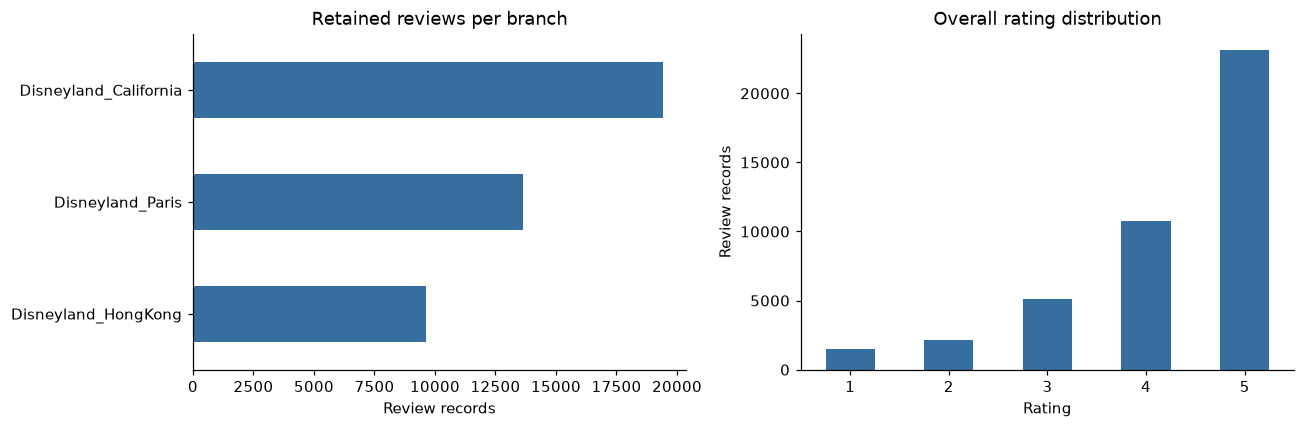

In [6]:
branch_summary = df.groupby("Branch").agg(
    review_count=("row_id", "size"), valid_ratings=("rating", "count"),
    mean_rating=("rating", "mean"), median_rating=("rating", "median"),
    text_reviews=("has_text", "sum"),
    first_month=("review_month", "min"), last_month=("review_month", "max")
).sort_values("review_count", ascending=False)
branch_summary["review_share_pct"] = 100 * branch_summary["review_count"] / len(df)
display(branch_summary.round(2))

rating_counts = df["rating"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
rating_by_branch = pd.crosstab(df["Branch"], df["rating"]).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
rating_pct = rating_by_branch.div(rating_by_branch.sum(axis=1).replace(0, np.nan), axis=0) * 100
display(rating_by_branch)
display(rating_pct.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
branch_summary["review_count"].sort_values().plot.barh(ax=axes[0], color="#356e9f")
axes[0].set(title="Retained reviews per branch", xlabel="Review records", ylabel="")
rating_counts.plot.bar(ax=axes[1], color="#356e9f", rot=0)
axes[1].set(title="Overall rating distribution", xlabel="Rating", ylabel="Review records")
plt.tight_layout()
plt.show()

### 1.4 Reviewer-location and time coverage
The cross-tab counts reviews for each reviewer-location/branch pair. A zero means no observed reviews in this file, not that visitors from that location never visit. Small groups produce unstable averages. We flag groups below 30 reviews as a practical inspection aid, not a statistical guarantee.

Known location labels: 162


,review_count,valid_ratings,mean_rating,branches_observed,review_share_pct
Reviewer_Location,,,,,
United States,14545,14545,4.32,3,34.11
United Kingdom,9751,9751,4.05,3,22.87
Australia,4677,4677,4.31,3,10.97
Canada,2234,2234,4.30,3,5.24
India,1511,1511,4.44,3,3.54
Philippines,1070,1070,4.40,3,2.51
Singapore,1035,1035,4.02,3,2.43
New Zealand,756,756,4.38,3,1.77
Malaysia,587,587,4.23,3,1.38


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
Reviewer_Location,,,
United States,12337,878,1330
United Kingdom,1019,740,7992
Australia,2448,1634,595
Canada,1842,204,188
India,135,1083,293
Philippines,55,991,24
Singapore,93,850,92
New Zealand,527,167,62
Malaysia,30,506,51


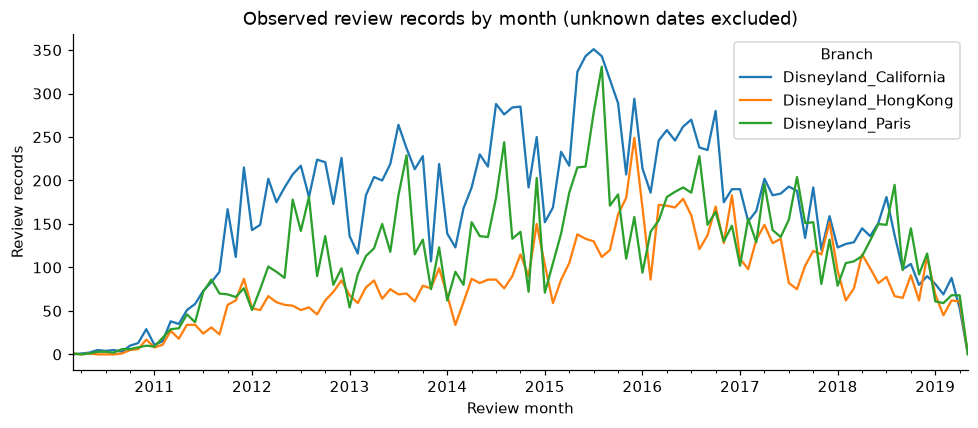

In [7]:
location_summary = df.groupby("Reviewer_Location").agg(
    review_count=("row_id", "size"), valid_ratings=("rating", "count"),
    mean_rating=("rating", "mean"), branches_observed=("Branch", "nunique")
).sort_values("review_count", ascending=False)
location_summary["review_share_pct"] = 100 * location_summary["review_count"] / len(df)
location_branch_counts = pd.crosstab(df["Reviewer_Location"], df["Branch"])
location_branch_summary = df.groupby(["Reviewer_Location", "Branch"]).agg(
    review_count=("row_id", "size"), mean_rating=("rating", "mean")
).reset_index()
location_branch_summary["small_group"] = location_branch_summary["review_count"] < 30
print("Known location labels:", df.loc[df["Reviewer_Location"] != "Unknown", "Reviewer_Location"].nunique())
display(location_summary.head(15).round(2))
display(location_branch_counts.loc[location_summary.head(15).index])

monthly_counts = df.dropna(subset=["review_month"]).groupby(["review_month", "Branch"]).size().unstack(fill_value=0)
if not monthly_counts.empty:
    monthly_counts.plot(title="Observed review records by month (unknown dates excluded)")
    plt.ylabel("Review records")
    plt.xlabel("Review month")
    plt.tight_layout()
    plt.show()

**Pause and write your interpretation:** Which branch has the most reviews? Is the rating distribution mostly high or low? Which locations dominate? How many dates cannot be used? Could uneven coverage affect comparisons? Describe this dataset, not all Disneyland visitors.

## 2. Clean text for its intended use
We keep three versions:

| Version | Use | What it preserves |
|---|---|---|
| `Review_Text` | Original evidence | Original text |
| `sentiment_text` | Sentiment and phrase matching | Punctuation, capitalization, negation |
| `clean_text` | Bag-of-words / TF-IDF | Lowercase words and numbers; expanded common negations |

Do not feed heavily cleaned text into sentiment: `not good` must not become `good`. We do not stem words because readable attraction names are useful here. This is a simple English pipeline; it does not translate or establish the language of every review. Non-English and mixed-language reviews need manual inspection.

In [8]:
def prepare_sentiment_text(value):
    """Remove markup/URLs and normalize spaces; keep tone and negation."""
    if pd.isna(value):
        return ""
    text = html.unescape(str(value)).replace("’", "'")
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def clean_for_terms(text):
    """Produce readable lowercase tokens without removing negation."""
    text = text.lower()
    text = re.sub(r"\bcan't\b", "cannot", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["sentiment_text"] = df["Review_Text"].apply(prepare_sentiment_text)
df["clean_text"] = df["sentiment_text"].apply(clean_for_terms)
df["word_count"] = df["clean_text"].str.split().str.len()
text_df = df.loc[df["clean_text"].str.contains(r"\w", regex=True)].copy().reset_index(drop=True)
if text_df.empty:
    raise ValueError("No text remains after cleaning; inspect the source column.")
print("Text-analysis records:", len(text_df))
print("Excluded from text analysis:", len(df) - len(text_df))
display(text_df[["row_id", "Review_Text", "clean_text", "word_count"]].head(3))
display(text_df["word_count"].describe().round(1))

Text-analysis records: 42644
Excluded from text analysis: 0


,row_id,Review_Text,clean_text,word_count
0,0,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very similar in the layout whe...,if you ve ever been to disneyland anywhere you ll find disneyland hong kong very similar in the layout whe...,61
1,1,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only stay in Tomorrowland ....",its been a while since d last time we visit hk disneyland yet this time we only stay in tomorrowland aka m...,175
2,2,Thanks God it wasn t too hot or too humid when I was visiting the park otherwise it would be a big iss...,thanks god it wasn t too hot or too humid when i was visiting the park otherwise it would be a big issue t...,177


count    42644.0
mean       132.0
std        157.8
min          3.0
25%         45.0
50%         83.0
75%        159.0
max       4000.0
Name: word_count, dtype: float64

## 3. Bag-of-words (BoW): count the words
A document is one review. A corpus is the collection of reviews. A vocabulary is the set of selected terms. Bag-of-words ignores overall word order and counts each term.

First, use a tiny made-up example where you can check every number. As in your professor's notebook, `fit` learns the vocabulary and `transform` converts text into numbers. `fit_transform` combines both steps.

In [9]:
toy_reviews = ["good ride good staff", "good food", "long queue"]
toy_vectorizer = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
toy_vectorizer.fit(toy_reviews)
toy_bow = toy_vectorizer.transform(toy_reviews)
display(pd.DataFrame(toy_bow.toarray(), columns=toy_vectorizer.get_feature_names_out(),
                     index=toy_reviews))  # Dense conversion is safe for this tiny example.

,food,good,long,queue,ride,staff
good ride good staff,0,2,0,0,1,1
good food,1,1,0,0,0,0
long queue,0,0,1,1,0,0


### 3.1 Apply BoW to the reviews
We use scikit-learn's built-in English stopwords so no corpus download is needed, and keep `no`, `not`, `never`, and `cannot`. This differs slightly from your professor's NLTK stopword list.

Parameters: `min_df=5` keeps terms found in at least five reviews; `max_df=0.95` excludes terms in over 95% of reviews; `max_features=15000` limits memory. These choices omit some rare attraction names from the vocabulary, so phrase matching later uses the original text. We use **single words** here; a separate bigram example preserves adjacent words without stopword removal.

The result is a **sparse matrix**, which stores mainly nonzero counts. Never turn the full review-by-word matrix into a dense DataFrame: it can consume gigabytes.

Matrix shape (reviews, terms): (42644, 12414)
Stored nonzero entries: 2006342
Reviews with no retained vocabulary terms: 0


,term,total_occurrences,reviews_containing_term,review_pct
7526,not,57471,24459,57.36
7950,park,45342,21425,50.24
3557,disney,37134,18983,44.52
9343,rides,35002,20676,48.49
3563,disneyland,33555,19792,46.41
11203,time,29895,17741,41.60
3156,day,28907,16476,38.64
9339,ride,18064,10195,23.91
6258,just,16681,11072,25.96
5202,great,16630,12075,28.32


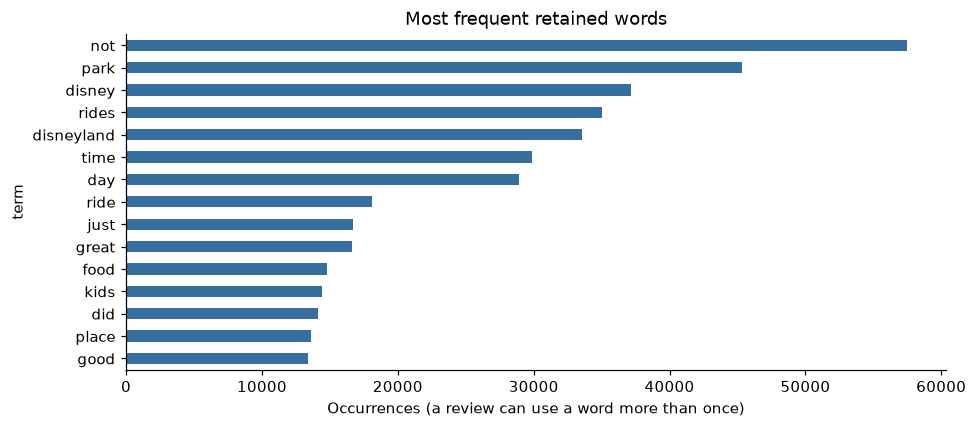

In [10]:
stop_words = sorted(set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "cannot"})
count_vectorizer = CountVectorizer(
    lowercase=False,               # Already lowercase in clean_text.
    stop_words=stop_words,
    token_pattern=r"(?u)\b\w\w+\b",  # Tokens with at least two characters.
    min_df=5, max_df=0.95, max_features=15000
)
bow = count_vectorizer.fit_transform(text_df["clean_text"])
terms = count_vectorizer.get_feature_names_out()
print("Matrix shape (reviews, terms):", bow.shape)
print("Stored nonzero entries:", bow.nnz)
print("Reviews with no retained vocabulary terms:", int((bow.getnnz(axis=1) == 0).sum()))

term_summary = pd.DataFrame({
    "term": terms,
    "total_occurrences": np.asarray(bow.sum(axis=0)).ravel(),
    "reviews_containing_term": np.asarray((bow > 0).sum(axis=0)).ravel()
})
term_summary["review_pct"] = 100 * term_summary["reviews_containing_term"] / len(text_df)
term_summary = term_summary.sort_values("total_occurrences", ascending=False)
display(term_summary.head(20).round(2))
term_summary.head(15).sort_values("total_occurrences").plot.barh(
    x="term", y="total_occurrences", legend=False, color="#356e9f")
plt.title("Most frequent retained words")
plt.xlabel("Occurrences (a review can use a word more than once)")
plt.tight_layout()
plt.show()

### 3.2 Explore two-word phrases
A bigram contains two consecutive tokens, such as `space mountain` or `long queues`. Keeping stopwords in this separate example prevents phrases from being created by deleting intervening words. Punctuation removal can still join words across sentence boundaries, so inspect original excerpts before adding a phrase rule.

In [11]:
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words=None,
                                   min_df=5, max_features=10000)
bigrams = bigram_vectorizer.fit_transform(text_df["clean_text"])
bigram_summary = pd.DataFrame({
    "phrase": bigram_vectorizer.get_feature_names_out(),
    "reviews_containing_phrase": np.asarray((bigrams > 0).sum(axis=0)).ravel()
}).sort_values("reviews_containing_phrase", ascending=False)
display(bigram_summary.head(25))

,phrase,reviews_containing_phrase
5446,of the,15608
7705,the park,14867
3877,in the,13109
4207,it was,12209
704,and the,10922
2992,for the,10237
3745,if you,9791
8554,to the,9317
7764,the rides,9095
1097,at the,8148


## 4. TF-IDF: give less weight to words that appear everywhere
BoW asks **how often is a word used?** TF-IDF weights words by their frequency within a review and their rarity across reviews. A high score is not a sentiment score or proof of a complaint.

Slide 17 presents normalized term frequency multiplied by `log(N / document_frequency)`. Here, `TfidfTransformer` converts the **same BoW matrix**, making the comparison easy. Its defaults use raw counts, smoothed IDF `log((1 + N)/(1 + df)) + 1`, then normalize each review's vector to length 1. Thus the numeric values differ from a literal implementation of the slide, while retaining the same intuition.

In [12]:
toy_transformer = TfidfTransformer()
toy_tfidf = toy_transformer.fit_transform(toy_bow)
display(pd.DataFrame(toy_tfidf.toarray(), columns=toy_vectorizer.get_feature_names_out(),
                     index=toy_reviews).round(3))
display(pd.DataFrame({"term": toy_vectorizer.get_feature_names_out(),
                      "idf": toy_transformer.idf_}).round(3))

tfidf_transformer = TfidfTransformer()
tfidf = tfidf_transformer.fit_transform(bow)
tfidf_summary = pd.DataFrame({"term": terms,
    "mean_tfidf": np.asarray(tfidf.mean(axis=0)).ravel(),
    "idf": tfidf_transformer.idf_}).sort_values("mean_tfidf", ascending=False)
display(term_summary.head(20).merge(tfidf_summary, on="term").round(4))
display(tfidf_summary.head(20).round(4))

,food,good,long,queue,ride,staff
good ride good staff,0.000,0.732,0.000,0.000,0.481,0.481
good food,0.796,0.605,0.000,0.000,0.000,0.000
long queue,0.000,0.000,0.707,0.707,0.000,0.000


,term,idf
0,food,1.693
1,good,1.288
2,long,1.693
3,queue,1.693
4,ride,1.693
5,staff,1.693


,term,total_occurrences,reviews_containing_term,review_pct,mean_tfidf,idf
0,not,57471,24459,57.3563,0.0511,1.5559
1,park,45342,21425,50.2415,0.0452,1.6883
2,disney,37134,18983,44.5151,0.0402,1.8093
3,rides,35002,20676,48.4851,0.0389,1.7239
4,disneyland,33555,19792,46.4122,0.0396,1.7676
5,time,29895,17741,41.6026,0.0353,1.8770
6,day,28907,16476,38.6362,0.0346,1.9509
7,ride,18064,10195,23.9072,0.0226,2.4309
8,just,16681,11072,25.9638,0.0222,2.3484
9,great,16630,12075,28.3158,0.0289,2.2617


,term,mean_tfidf,idf
7526,not,0.0511,1.5559
7950,park,0.0452,1.6883
3557,disney,0.0402,1.8093
3563,disneyland,0.0396,1.7676
9343,rides,0.0389,1.7239
11203,time,0.0353,1.8770
3156,day,0.0346,1.9509
5202,great,0.0289,2.2617
8232,place,0.0254,2.4026
6296,kids,0.0240,2.4932


### 4.1 Inspect one review and compare branches
For an individual review, inspect its highest-weight terms beside the original text. For branches, use **one shared vocabulary and IDF fit on the full corpus**. Mean TF-IDF highlights prominent terms, but it does not automatically mean those terms are unique to a branch. We also calculate the difference from the mean in all other branches; it is a descriptive contrast, not a significance test.

In [13]:
REVIEW_POSITION = 0  # Position in text_df, not Review_ID.
print(text_df.iloc[REVIEW_POSITION]["Review_Text"])
one_review = tfidf.getrow(REVIEW_POSITION)
display(pd.DataFrame({"term": terms[one_review.indices], "tfidf": one_review.data})
        .sort_values("tfidf", ascending=False).head(15).round(4))

branch_term_tables = []
for branch in sorted(text_df["Branch"].unique()):
    mask = text_df["Branch"].eq(branch).to_numpy()
    branch_mean = np.asarray(tfidf[mask].mean(axis=0)).ravel()
    other_mean = (np.asarray(tfidf[~mask].mean(axis=0)).ravel()
                  if (~mask).any() else np.full(len(terms), np.nan))
    table = pd.DataFrame({"Branch": branch, "term": terms,
                          "mean_tfidf": branch_mean,
                          "difference_vs_others": branch_mean - other_mean})
    branch_term_tables.append(table)
    print("\n", branch, "| text records:", int(mask.sum()))
    display(table.sort_values("difference_vs_others", ascending=False).head(12).round(4))
branch_terms = pd.concat(branch_term_tables, ignore_index=True)

If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very similar in the layout when you walk into main street! It has a very familiar feel. One of the rides  its a Small World  is absolutely fabulous and worth doing. The day we visited was fairly hot and relatively busy but the queues moved fairly well.

 Disneyland_California | text records: 19404

 Disneyland_HongKong | text records: 9611

 Disneyland_Paris | text records: 13629


,term,tfidf
6,fairly,0.4721
7,familiar,0.2695
12,layout,0.2662
17,relatively,0.2446
15,moved,0.2388
5,fabulous,0.2153
19,similar,0.2142
4,doing,0.1918
0,absolutely,0.1761
13,ll,0.1733


,Branch,term,mean_tfidf,difference_vs_others
6567,Disneyland_California,lines,0.0237,0.0159
1931,Disneyland_California,california,0.0194,0.0159
678,Disneyland_California,adventure,0.0156,0.0132
3563,Disneyland_California,disneyland,0.0463,0.0123
7981,Disneyland_California,pass,0.0226,0.0117
6690,Disneyland_California,love,0.0222,0.0113
3005,Disneyland_California,crowds,0.0145,0.0105
3860,Disneyland_California,earth,0.0124,0.0103
5361,Disneyland_California,happiest,0.0116,0.0096
3003,Disneyland_California,crowded,0.0153,0.0092


,Branch,term,mean_tfidf,difference_vs_others
5596,Disneyland_HongKong,hong,0.0374,0.0368
6348,Disneyland_HongKong,kong,0.0374,0.0367
5541,Disneyland_HongKong,hk,0.0283,0.0281
10109,Disneyland_HongKong,small,0.0248,0.0156
7308,Disneyland_HongKong,mtr,0.0146,0.0146
6296,Disneyland_HongKong,kids,0.0338,0.0126
6576,Disneyland_HongKong,lion,0.0123,0.0121
6309,Disneyland_HongKong,king,0.0123,0.0119
11376,Disneyland_HongKong,train,0.0164,0.0115
3156,Disneyland_HongKong,day,0.0424,0.0101


,Branch,term,mean_tfidf,difference_vs_others
7947,Disneyland_Paris,paris,0.0332,0.0303
8755,Disneyland_Paris,queues,0.0243,0.0179
8752,Disneyland_Paris,queue,0.0199,0.0139
10417,Disneyland_Paris,staff,0.0221,0.0118
5654,Disneyland_Paris,hotel,0.0179,0.0115
7526,Disneyland_Paris,not,0.0583,0.0106
2277,Disneyland_Paris,children,0.0218,0.0104
10653,Disneyland_Paris,studios,0.0113,0.0102
2430,Disneyland_Paris,closed,0.0173,0.0101
3557,Disneyland_Paris,disney,0.0469,0.0099


**Pause:** Explain the difference between a word's total count and the number of reviews containing it. Find one informative attraction phrase and one possible complaint phrase. Read several original reviews before adding either to your dictionaries.

## 5. Identify attraction and service mentions
We use transparent, editable dictionaries rather than a complex model. A **label** is our consistent name; its **aliases** are phrases reviewers might use. Matching uses word boundaries, so `train` does not match inside `training`.

These are starter rules, not an official attraction inventory. Names can refer to other parks in comparisons. A mention in a branch's review does not prove the attraction exists there. Add aliases from your data and validate references manually. We deliberately avoid vague aliases like `mountain` or `pirates`.

In [14]:
ATTRACTIONS = {
    "Space Mountain": ["space mountain", "hyperspace mountain"],
    "It's a Small World": ["it's a small world", "its a small world", "small world"],
    "Pirates of the Caribbean": ["pirates of the caribbean"],
    "Big Thunder Mountain": ["big thunder mountain", "thunder mountain"],
    "Buzz Lightyear": ["buzz lightyear"],
    "Haunted Mansion": ["haunted mansion"],
    "Phantom Manor": ["phantom manor"],
    "Jungle Cruise": ["jungle cruise", "jungle river cruise"],
    "Iron Man Experience": ["iron man experience", "ironman experience"],
    "Mystic Manor": ["mystic manor"],
    "Ratatouille": ["ratatouille"],
    "Dumbo": ["dumbo"],
    "Railroad": ["disneyland railroad", "disney railroad"],
}
SERVICES = {
    "Staff / customer service": ["staff", "cast member", "cast members", "customer service", "employees"],
    "Food / dining": ["food", "restaurant", "restaurants", "food counter", "food counters", "meal", "meals", "dining"],
    "Tickets / admission": ["ticket", "tickets", "admission", "entry fee"],
    "Queue / fast pass": ["queue", "queues", "waiting time", "wait time", "fastpass", "fast pass"],
    "Cleanliness / toilets": ["toilet", "toilets", "restroom", "restrooms", "bathroom", "bathrooms", "cleanliness"],
    "Shows / entertainment": ["parade", "parades", "fireworks", "shows"],
    "Transport / parking": ["parking", "shuttle", "shuttles", "transport"],
}

In [15]:
def compile_aliases(dictionary):
    """Build one word-boundary pattern per label (longest aliases first)."""
    patterns = {}
    for label, aliases in dictionary.items():
        escaped = [re.escape(alias) for alias in sorted(aliases, key=len, reverse=True)]
        patterns[label] = re.compile(r"\b(?:" + "|".join(escaped) + r")\b", re.IGNORECASE)
    return patterns

attraction_patterns = compile_aliases(ATTRACTIONS)
service_patterns = compile_aliases(SERVICES)

def find_labels(text, patterns):
    return [label for label, pattern in patterns.items() if pattern.search(text)]

text_df["attraction_mentions"] = text_df["sentiment_text"].apply(
    lambda text: find_labels(text, attraction_patterns))
text_df["service_mentions"] = text_df["sentiment_text"].apply(
    lambda text: find_labels(text, service_patterns))
display(text_df[["row_id", "attraction_mentions", "service_mentions"]].head(10))
print("Reviews with a named attraction match:", text_df["attraction_mentions"].str.len().gt(0).sum())

Reviews with a named attraction match: 8107


,row_id,attraction_mentions,service_mentions
0,0,[It's a Small World],[Queue / fast pass]
1,1,"[Space Mountain, Buzz Lightyear, Iron Man Experience]",[Staff / customer service]
2,2,[],"[Food / dining, Queue / fast pass, Cleanliness / toilets, Shows / entertainment]"
3,3,[],[Food / dining]
4,4,[],[]
5,5,[],"[Food / dining, Tickets / admission, Shows / entertainment]"
6,6,[],[Shows / entertainment]
7,7,[],"[Staff / customer service, Food / dining]"
8,8,[],[Staff / customer service]
9,9,[Jungle Cruise],"[Tickets / admission, Shows / entertainment]"


## 6. Sentiment and complaint categories
**Three different things:** (1) an attraction/service mention, (2) the emotional tone of its nearby text, and (3) an operational complaint. A mention alone is not a complaint. `The queue was short` must not be counted as a long-queue complaint.

VADER is a rule-based English sentiment baseline. Its compound score ranges from -1 to +1; the usual cutoffs are ≤ -0.05 negative, ≥ 0.05 positive, otherwise neutral. A score of zero means little detected sentiment, not necessarily satisfaction. Overall ratings are kept separate: a five-star review can still complain about queues.

We split each review into punctuation-delimited sentences and contrast clauses (`but`, `however`, `although`, `yet`). Then we score each segment. This reduces the problem of applying one review-wide label to every aspect, but it is **approximate aspect sentiment**, not a trained aspect model. Multiple aspects in one segment share the same score and are flagged as ambiguous.

In [16]:
analyzer = SentimentIntensityAnalyzer()

def sentiment_label(score):
    if score >= 0.05:
        return "positive"
    if score <= -0.05:
        return "negative"
    return "neutral"

def split_segments(text):
    # A simple baseline: abbreviations can split incorrectly; pronouns are not resolved.
    parts = re.split(r"(?<=[.!?;])\s+|\b(?:but|however|although|yet)\b", text, flags=re.IGNORECASE)
    return [part.strip(" ,;") for part in parts if part.strip(" ,;")]

demo_text = "Space Mountain was amazing! But the staff were rude. The queue was short."
display(pd.DataFrame([
    {"segment": segment, **analyzer.polarity_scores(segment)}
    for segment in split_segments(demo_text)
]))

,segment,neg,neu,pos,compound
0,Space Mountain was amazing!,0.0,0.423,0.577,0.6239
1,the staff were rude.,0.5,0.500,0.000,-0.4588
2,The queue was short.,0.0,1.000,0.000,0.0000


### 6.1 Editable complaint rules
A category has **topic phrases** and more specific **problem cues**. We mark a candidate when a topic has negative segment sentiment or when an explicit cue matches, even if VADER is neutral (for example, `ride was closed`). We store the reason and evidence.

A small negation guard ignores cues preceded by phrases such as `no`, `not`, or `never` within three words. This is imperfect: double negation, sarcasm, quoted complaints, and `not only` need inspection. A positive segment containing an explicit cue can still be a candidate because operational inconvenience may coexist with praise.

Every detected complaint is a **candidate for validation**, not a confirmed label. Zero detected complaints means no rule fired; it does not prove a positive experience.

Closures/breakdowns and food-counter overcrowding require an explicit problem cue; general negative sentiment alone is not sufficient for these categories.

In [17]:
COMPLAINT_TOPICS = {
    "Long queues": ["queue", "queues", "wait", "waiting", "line", "lines"],
    "Closures / breakdowns": ["ride", "rides", "attraction", "attractions", "closed", "closure", "maintenance"],
    "Poor staff service": ["staff", "cast member", "cast members", "employees", "customer service"],
    "High prices / poor value": ["price", "prices", "cost", "expensive", "overpriced", "value", "money"],
    "Food quality / dining": ["food", "restaurant", "restaurants", "meal", "meals", "food counter"],
    "Crowding": ["crowded", "overcrowded", "crowds", "crowd", "packed"],
    "Cleanliness": ["dirty", "filthy", "toilet", "toilets", "restroom", "bathroom", "cleanliness"],
    "Food counter overcrowding": ["food counter", "food counters", "restaurant", "restaurants", "dining"],
}
COMPLAINT_CUES = {
    "Long queues": ["long queue", "long queues", "long wait", "long waits", "long lines", "long line", "waited an hour", "waited for an hour"],
    "Closures / breakdowns": ["closed", "broken down", "broke down", "not working", "out of service", "under maintenance"],
    "Poor staff service": ["rude", "unhelpful", "unfriendly", "poor service", "bad service", "ignored us"],
    "High prices / poor value": ["expensive", "overpriced", "too costly", "poor value", "waste of money", "not worth"],
    "Food quality / dining": ["cold food", "bad food", "terrible food", "poor food", "stale", "undercooked"],
    "Crowding": ["overcrowded", "too crowded", "very crowded", "extremely crowded"],
    "Cleanliness": ["dirty", "filthy", "unclean"],
    "Food counter overcrowding": ["overcrowded", "too crowded", "long queue", "long queues", "long lines", "packed"],
}
topic_patterns = compile_aliases(COMPLAINT_TOPICS)
cue_patterns = compile_aliases(COMPLAINT_CUES)

In [18]:
def is_negated(text, start):
    """Small, inspectable guard; not a complete grammatical negation parser."""
    prefix = text[max(0, start - 50):start].lower()
    words = re.findall(r"\b[\w']+\b", prefix)[-3:]
    negatives = {"no", "not", "never", "without", "hardly", "wasn't", "weren't", "isn't", "aren't"}
    return any(word in negatives for word in words)

def detect_complaints(segment, compound):
    """Return category, evidence and rule reason for each candidate."""
    results = []
    for category, topic_pattern in topic_patterns.items():
        if not topic_pattern.search(segment):
            continue
        cue_matches = list(cue_patterns[category].finditer(segment))
        active_cues = [match.group() for match in cue_matches if not is_negated(segment, match.start())]
        # Don't let unrelated negative words revive an explicitly negated problem cue.
        all_cues_negated = bool(cue_matches) and not active_cues
        if active_cues:
            results.append((category, "; ".join(active_cues), "explicit_problem_cue"))
        elif compound <= -0.05 and not all_cues_negated and category not in {"Food counter overcrowding", "Closures / breakdowns"}:
            results.append((category, topic_pattern.search(segment).group(), "negative_segment_plus_topic"))
    return results

examples = ["The queue was short.", "There were no long queues.",
            "Space Mountain was closed.", "Space Mountain was not closed.",
            "The staff were rude.", "The food counter was overcrowded."]
display(pd.DataFrame([
    {"example": text, "compound": analyzer.polarity_scores(text)["compound"],
     "candidate_categories": [item[0] for item in detect_complaints(text, analyzer.polarity_scores(text)["compound"])]}
    for text in examples
]))

,example,compound,candidate_categories
0,The queue was short.,0.0000,[]
1,There were no long queues.,-0.2960,[]
2,Space Mountain was closed.,0.0000,[Closures / breakdowns]
3,Space Mountain was not closed.,0.0000,[]
4,The staff were rude.,-0.4588,[Poor staff service]
5,The food counter was overcrowded.,0.0000,"[Crowding, Food counter overcrowding]"


### 6.2 Run the extraction on all usable reviews
`mentions` has one row per segment/aspect label. `complaints` has one row per segment/category. We preserve review keys, branch, location, segment text, score and evidence.

Complaint-to-attraction linking is tentative: if exactly one named attraction appears in the same segment, save it as a **candidate** link. With none, leave it unlinked. With more than one, mark it ambiguous. A service complaint can occur beside an attraction name without being caused by that attraction, so inspect every link used for recommendations.

In [19]:
mention_rows = []
complaint_rows = []
review_scores = []

for position, row in enumerate(text_df.itertuples(index=False)):
    review_scores.append(analyzer.polarity_scores(row.sentiment_text)["compound"])
    for segment_id, segment in enumerate(split_segments(row.sentiment_text)):
        score = analyzer.polarity_scores(segment)["compound"]
        attractions = find_labels(segment, attraction_patterns)
        services = find_labels(segment, service_patterns)
        common = {"row_id": row.row_id, "Review_ID": row.Review_ID,
                  "Branch": row.Branch, "Reviewer_Location": row.Reviewer_Location,
                  "segment_id": segment_id, "segment": segment,
                  "compound": score, "sentiment": sentiment_label(score)}
        for kind, labels in [("attraction", attractions), ("service", services)]:
            for label in labels:
                mention_rows.append({**common, "aspect_type": kind, "aspect": label,
                                     "multiple_aspects_in_segment": len(attractions) + len(services) > 1})
        for category, evidence, reason in detect_complaints(segment, score):
            complaint_rows.append({**common, "category": category,
                "evidence": evidence, "rule_reason": reason,
                "candidate_attraction": attractions[0] if len(attractions) == 1 else None,
                "link_status": "candidate_same_segment" if len(attractions) == 1 else
                               "ambiguous_multiple_attractions" if len(attractions) > 1 else "unlinked",
                "service_mentions": services})
    if (position + 1) % 10000 == 0:
        print(f"Processed {position + 1:,} / {len(text_df):,} reviews")

common_columns = ["row_id", "Review_ID", "Branch", "Reviewer_Location", "segment_id", "segment", "compound", "sentiment"]
mentions = pd.DataFrame(mention_rows, columns=common_columns +
                       ["aspect_type", "aspect", "multiple_aspects_in_segment"])
complaints = pd.DataFrame(complaint_rows, columns=common_columns +
                         ["category", "evidence", "rule_reason", "candidate_attraction", "link_status", "service_mentions"])
text_df["review_compound"] = review_scores
text_df["review_sentiment"] = text_df["review_compound"].apply(sentiment_label)
print("Mention records:", len(mentions), "| Complaint candidate records:", len(complaints))
display(mentions.head(5))
display(complaints.head(5))

Processed 10,000 / 42,644 reviews
Processed 20,000 / 42,644 reviews
Processed 30,000 / 42,644 reviews
Processed 40,000 / 42,644 reviews
Mention records: 96966 | Complaint candidate records: 34828


,row_id,Review_ID,Branch,Reviewer_Location,segment_id,segment,compound,sentiment,aspect_type,aspect,multiple_aspects_in_segment
0,0,670772142,Disneyland_HongKong,Australia,2,One of the rides its a Small World is absolutely fabulous and worth doing.,0.7056,positive,attraction,It's a Small World,False
1,0,670772142,Disneyland_HongKong,Australia,4,the queues moved fairly well.,0.2732,positive,service,Queue / fast pass,False
2,1,670682799,Disneyland_HongKong,Philippines,2,AKA Marvel land!Now they have Iron Man Experience n d Newly open Ant Man n d Wasp!!Ironman ..,0.5684,positive,attraction,Iron Man Experience,False
3,1,670682799,Disneyland_HongKong,Philippines,4,Changed by previous Buzz lightyear!,0.0000,neutral,attraction,Buzz Lightyear,False
4,1,670682799,Disneyland_HongKong,Philippines,7,my boys like it!!Space Mountain ..,0.4738,positive,attraction,Space Mountain,False


,row_id,Review_ID,Branch,Reviewer_Location,segment_id,segment,compound,sentiment,category,evidence,rule_reason,candidate_attraction,link_status,service_mentions
0,2,670623270,Disneyland_HongKong,United Arab Emirates,4,The park itself is quite small (I was really expecting something grand even the main castle which was clos...,0.8428,positive,Closures / breakdowns,closed,explicit_problem_cue,NaN,unlinked,[Food / dining]
1,3,670607911,Disneyland_HongKong,Australia,1,Unfortunately there is quite a bit of maintenance work going on at present so a number of areas are closed...,-0.1585,negative,Closures / breakdowns,closed,explicit_problem_cue,NaN,unlinked,[]
2,5,670591897,Disneyland_HongKong,Singapore,3,"Souvenirs, food and even entrance tickets are slightly more expensive than other Disneyland as well.",0.2732,positive,High prices / poor value,expensive,explicit_problem_cue,NaN,unlinked,"[Food / dining, Tickets / admission]"
3,5,670591897,Disneyland_HongKong,Singapore,7,was VERY expensive,0.0000,neutral,High prices / poor value,expensive,explicit_problem_cue,NaN,unlinked,[]
4,5,670591897,Disneyland_HongKong,Singapore,11,"what was the problem was the people were just so rude, the pushing and shoving cutting in lines for the ri...",-0.6329,negative,Long queues,lines,negative_segment_plus_topic,NaN,unlinked,[Food / dining]


### 6.3 Summarize mentions and candidate complaints
Repeated mentions by one review should not inflate review counts. For aspect sentiment, first average segments within each review/aspect, then summarize those review-level results. Mixed positive/negative segments can cancel, so we also flag mixed sentiment.

Complaint percentages below divide **unique reviews with a candidate category** by **all usable text reviews in that branch**. One review may have several categories, so percentages need not add to 100%. Missing-text reviews are excluded from this denominator.

,Branch,aspect_type,aspect,review_count,mean_compound,mixed_review_count,negative_review_pct
50,Disneyland_Paris,service,Food / dining,5678,0.168,668,23.846
51,Disneyland_Paris,service,Queue / fast pass,5647,0.167,803,21.923
52,Disneyland_Paris,service,Shows / entertainment,5030,0.419,276,9.185
13,Disneyland_California,service,Shows / entertainment,4568,0.359,244,11.515
11,Disneyland_California,service,Food / dining,4525,0.279,232,14.099
12,Disneyland_California,service,Queue / fast pass,4139,0.240,231,13.361
33,Disneyland_HongKong,service,Shows / entertainment,3838,0.375,196,8.833
53,Disneyland_Paris,service,Staff / customer service,3728,0.288,376,25.268
14,Disneyland_California,service,Staff / customer service,3212,0.424,195,14.103
31,Disneyland_HongKong,service,Food / dining,2928,0.225,140,17.111


,Branch,category,candidate_review_count,text_review_count,candidate_review_pct
0,Disneyland_California,Long queues,3102,19404,15.99
1,Disneyland_California,Closures / breakdowns,1595,19404,8.22
2,Disneyland_California,Poor staff service,617,19404,3.18
3,Disneyland_California,High prices / poor value,2706,19404,13.95
4,Disneyland_California,Food quality / dining,819,19404,4.22
5,Disneyland_California,Crowding,1672,19404,8.62
6,Disneyland_California,Cleanliness,146,19404,0.75
7,Disneyland_California,Food counter overcrowding,31,19404,0.16
8,Disneyland_HongKong,Long queues,1207,9611,12.56
9,Disneyland_HongKong,Closures / breakdowns,428,9611,4.45


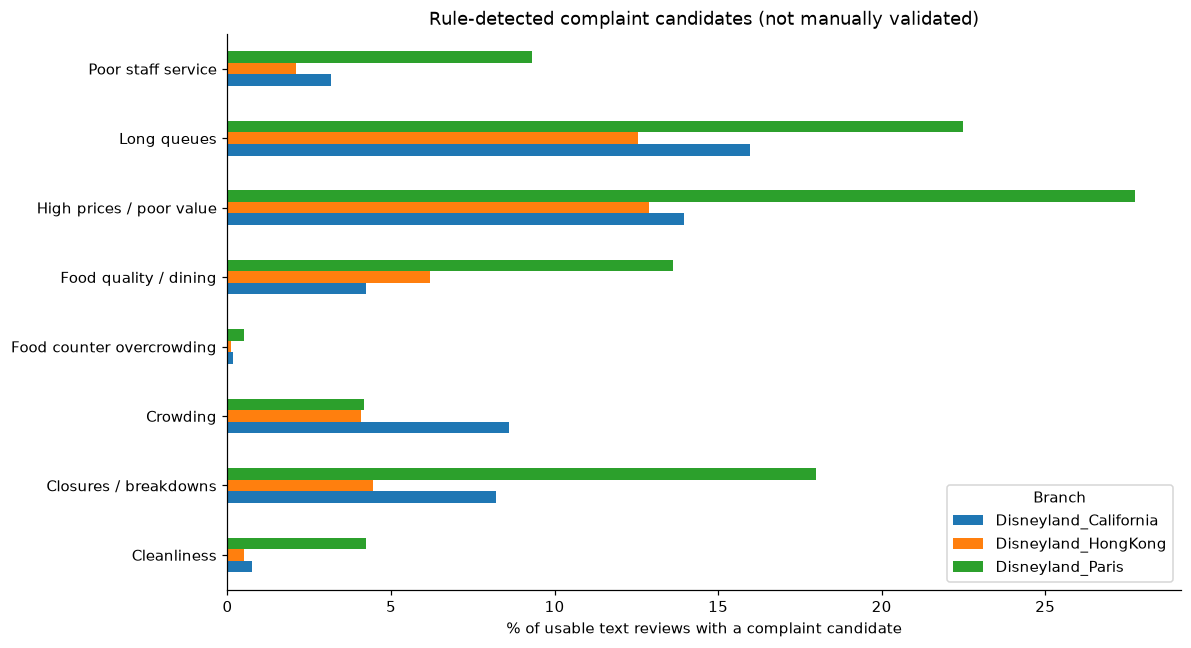

In [20]:
aspect_review = mentions.groupby(["row_id", "Branch", "aspect_type", "aspect"]).agg(
    mean_compound=("compound", "mean"), segment_count=("segment_id", "nunique"),
    any_positive=("compound", lambda values: (values >= 0.05).any()),
    any_negative=("compound", lambda values: (values <= -0.05).any())
).reset_index()
aspect_review["mixed_sentiment"] = aspect_review["any_positive"] & aspect_review["any_negative"]
aspect_review["aspect_sentiment"] = aspect_review["mean_compound"].apply(sentiment_label)
aspect_summary = aspect_review.groupby(["Branch", "aspect_type", "aspect"]).agg(
    review_count=("row_id", "nunique"), mean_compound=("mean_compound", "mean"),
    mixed_review_count=("mixed_sentiment", "sum"),
    negative_review_pct=("aspect_sentiment", lambda values: 100 * values.eq("negative").mean())
).reset_index().sort_values("review_count", ascending=False)
display(aspect_summary.head(20).round(3))

branch_denominators = text_df.groupby("Branch").size().rename("text_review_count")
category_counts = complaints.groupby(["Branch", "category"])["row_id"].nunique()
all_pairs = pd.MultiIndex.from_product([branch_denominators.index, COMPLAINT_TOPICS], names=["Branch", "category"])
complaint_summary = category_counts.reindex(all_pairs, fill_value=0).rename("candidate_review_count").reset_index()
complaint_summary = complaint_summary.merge(branch_denominators, on="Branch")
complaint_summary["candidate_review_pct"] = 100 * complaint_summary["candidate_review_count"] / complaint_summary["text_review_count"]
display(complaint_summary.round(2))
complaint_summary.pivot(index="category", columns="Branch", values="candidate_review_pct").plot.barh(figsize=(11, 6))
plt.xlabel("% of usable text reviews with a complaint candidate")
plt.title("Rule-detected complaint candidates (not manually validated)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 6.4 Compare overall sentiment with ratings (a reasonableness check)
We label ratings 1–2 low, 3 middle, and 4–5 high only for this descriptive comparison. Rating agreement is **not accuracy**: the rating is for the whole visit and may differ from the tone of individual aspects. Read mismatches rather than forcing the text score to agree with the rating.

In [21]:
text_df["rating_band"] = text_df["rating"].map({1: "low", 2: "low", 3: "middle", 4: "high", 5: "high"}).fillna("unknown")
display(pd.crosstab(text_df["rating_band"], text_df["review_sentiment"]))
mismatch = ((text_df["rating_band"].eq("high") & text_df["review_sentiment"].eq("negative")) |
            (text_df["rating_band"].eq("low") & text_df["review_sentiment"].eq("positive")))
display(text_df.loc[mismatch, ["row_id", "rating", "review_compound", "Review_Text"]].head(5))

review_sentiment,negative,neutral,positive
rating_band,,,
high,1346,462,32103
low,1659,91,1876
middle,1162,149,3796


,row_id,rating,review_compound,Review_Text
8,8,2,0.5195,"Feel so let down with this place,the Disneyland train was fantastic until you get past the station,bad sig..."
12,12,4,-0.7789,"We spend two days, the second day went early then went straight to the back of the park, no lineups for so..."
28,28,5,-0.5574,We visited here on a Wednesday. We arrived for opening and found the queue times to be short and had done ...
71,71,4,-0.7430,During a recent stop over in Hong Kong we paid a return trip to Disney. We chose a day when the park was q...
72,72,4,-0.3400,We had an impromptu trip to Disneyland on a weekday. I love the trip because there is no wait time or at l...


## 7. Manually validate before treating labels as findings
The extraction is complete as a runnable baseline; the labels are not ground truth. Inspect examples from every branch, category, and sentiment, plus reviews where nothing was detected. The random whole-review sample below helps find missed complaints; checking detected rows alone cannot establish recall.

Fill the blank columns in copies of the exported validation CSVs. For each detection, mark `correct`, `incorrect`, or `unclear`; record corrected sentiment and attraction link where needed. For a whole review, list all true categories as a JSON list such as `["Long queues"]`, or `[]` for none. Leave uncertain cases for discussion.

Use one set of examples to revise dictionaries and a separate untouched set to evaluate the revised rules. Report precision/recall only after human labels exist. For a category: precision = correct detected reviews / all detected reviews; recall = correctly detected reviews / all human-labeled positive reviews. These calculations require the same manually labeled review sample, including negative cases.

In [22]:
# A few examples per branch/category, including rarer detected categories.
validation_parts = []
for _, group in complaints.groupby(["Branch", "category"]):
    validation_parts.append(group.sample(n=min(3, len(group)), random_state=RANDOM_SEED))
complaint_validation = (pd.concat(validation_parts, ignore_index=True)
                        if validation_parts else complaints.copy())
for column in ["human_complaint_label", "human_sentiment", "human_attraction_link", "notes"]:
    complaint_validation[column] = ""

mention_parts = []
for _, group in mentions.groupby(["Branch", "aspect_type", "sentiment"]):
    mention_parts.append(group.sample(n=min(3, len(group)), random_state=RANDOM_SEED))
mention_validation = pd.concat(mention_parts, ignore_index=True) if mention_parts else mentions.copy()
for column in ["human_mention_label", "human_sentiment", "notes"]:
    mention_validation[column] = ""

review_parts = []
for _, group in text_df.groupby("Branch"):
    review_parts.append(group.sample(n=min(20, len(group)), random_state=RANDOM_SEED))
review_validation = pd.concat(review_parts)[["row_id", "Review_ID", "Branch", "Review_Text"]].copy()
review_validation["human_categories_json"] = ""
review_validation["notes"] = ""
display(complaint_validation[["Branch", "category", "segment", "evidence", "sentiment"]].head(10))

,Branch,category,segment,evidence,sentiment
0,Disneyland_California,Cleanliness,"Unfortunately Disneyland is past it's glory days, tickets are overpriced compared to other parks, even mid...",dirty,positive
1,Disneyland_California,Cleanliness,"The overall cleanliness of the park left something to be desired as well, with dirty bathrooms the norm, a...",dirty,positive
2,Disneyland_California,Cleanliness,"We found the parks to be dirty, cast members to be rude, crowds in the park, not really family oriented an...",dirty,negative
3,Disneyland_California,Closures / breakdowns,The rides are pretty outdated and some of the best ones broke down while we were at the park (Indiana Jone...,broke down,positive
4,Disneyland_California,Closures / breakdowns,So make sure you look at Disney s web site to see what is open and what is closed.,closed,positive
5,Disneyland_California,Closures / breakdowns,"Splash Mountain, Big Thunder Railroad, Indiana Jones, Astro Blasters, Space Mountain, and Star Tours are t...",closed,positive
6,Disneyland_California,Crowding,"3) Overpriced from the funnel cakes, drinks and the ice cream bars to the poorly prepared and pathetically...",crowded,negative
7,Disneyland_California,Crowding,"In this way we avoided the initial crowds, though in the end they cannot be avoided.Be clear about which t...",crowds,negative
8,Disneyland_California,Crowding,miss some of them as the crowd was to big for everyone to get their pictures taken.,crowd,negative
9,Disneyland_California,Food counter overcrowding,even so there is a lot of walking and standing in queues involved so wear your most comfortable shoes (no ...,long queues,positive


## 8. Prepare the handoff tables
Each retained review gets one transaction row and a deduplicated list of **candidate** complaint categories. Keep empty lists: dropping them would inflate later frequent-itemset support. `text_eligible` lets teammates choose the appropriate denominator. Attraction mentions stay keyed by `Branch` and `row_id` so names are not accidentally combined across parks.

The saved CSVs use UTF-8 with a BOM for easier opening in Excel. List-valued columns are saved as JSON strings; Python can recover them with `json.loads`. A timestamped run folder avoids overwriting manual validation work. Only compact tables, not the huge word matrices, are exported.

In [23]:
category_lists = complaints.groupby("row_id")["category"].agg(lambda values: sorted(set(values)))
transactions = df[["row_id", "Review_ID", "Branch", "Reviewer_Location", "rating"]].copy()
transactions["text_eligible"] = transactions["row_id"].isin(text_df["row_id"])
transactions["candidate_categories"] = transactions["row_id"].apply(lambda key: category_lists.get(key, []))
transactions["candidate_category_count"] = transactions["candidate_categories"].str.len()
assert len(transactions) == len(df)
assert transactions["row_id"].is_unique
assert set(complaints["row_id"]).issubset(set(text_df["row_id"]))
assert (complaint_summary["candidate_review_count"] <= complaint_summary["text_review_count"]).all()
display(transactions.head())

run_dir = OUTPUT_DIR / pd.Timestamp.now().strftime("run_%Y%m%d_%H%M%S_%f")
run_dir.mkdir(parents=True, exist_ok=False)

def save_table(table, filename, list_columns=()):
    export = table.copy()
    for column in list_columns:
        export[column] = export[column].apply(lambda value: json.dumps(value, ensure_ascii=False))
    export.to_csv(run_dir / filename, index=False, encoding="utf-8-sig")

save_table(missing_summary, "01_missing_values.csv")
save_table(branch_summary.reset_index(), "02_branch_coverage.csv")
save_table(location_summary.reset_index(), "03_location_coverage.csv")
save_table(location_branch_summary, "04_location_branch_coverage.csv")
save_table(term_summary, "05_bow_terms.csv")
save_table(bigram_summary, "06_bigram_terms.csv")
save_table(tfidf_summary, "07_tfidf_terms.csv")
save_table(branch_terms.sort_values("difference_vs_others", ascending=False).groupby("Branch").head(50), "08_branch_tfidf_terms.csv")
save_table(mentions, "09_segment_mentions.csv")
save_table(complaints, "10_complaint_candidates.csv", ["service_mentions"])
save_table(aspect_summary, "11_aspect_summary.csv")
save_table(complaint_summary, "12_complaint_summary.csv")
save_table(transactions, "13_review_transactions.csv", ["candidate_categories"])
save_table(complaint_validation, "14_validate_complaints.csv", ["service_mentions"])
save_table(mention_validation, "15_validate_mentions.csv")
save_table(review_validation, "16_validate_whole_reviews.csv")
save_table(text_df, "17_reviews_with_text_features.csv", ["attraction_mentions", "service_mentions"])

metadata = {"input_file": str(DATA_PATH), "encoding": encoding_used,
            "raw_rows": len(raw), "exact_duplicates_removed": exact_duplicates,
            "retained_rows": len(df), "text_rows": len(text_df),
            "python_version": platform.python_version(),
            "packages": {name: importlib.metadata.version(name) for name in
                         ["pandas", "numpy", "scikit-learn", "matplotlib", "vaderSentiment"]},
            "bow_settings": {"min_df": 5, "max_df": 0.95, "max_features": 15000},
            "sentiment_thresholds": {"negative_max": -0.05, "positive_min": 0.05},
            "attraction_aliases": ATTRACTIONS, "service_aliases": SERVICES,
            "complaint_topics": COMPLAINT_TOPICS, "complaint_cues": COMPLAINT_CUES,
            "label_status": "Automatic candidates; human validation required"}
(run_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved outputs to:", run_dir.resolve())
print("Keep this notebook with the exports to preserve the full preprocessing and matching logic.")

Saved outputs to: C:\Users\jlgel\Downloads\BDCC-Lab1-\outputs\disneyland_analysis\run_20261017_161430_391340
Keep this notebook with the exports to preserve the full preprocessing and matching logic.


,row_id,Review_ID,Branch,Reviewer_Location,rating,text_eligible,candidate_categories,candidate_category_count
0,0,670772142,Disneyland_HongKong,Australia,4,True,[],0
1,1,670682799,Disneyland_HongKong,Philippines,4,True,[],0
2,2,670623270,Disneyland_HongKong,United Arab Emirates,4,True,[Closures / breakdowns],1
3,3,670607911,Disneyland_HongKong,Australia,4,True,[Closures / breakdowns],1
4,4,670607296,Disneyland_HongKong,United Kingdom,4,True,[],0


## 9. Frequent itemset mining and association rules
TF-IDF describes words; FIM describes **sets of complaint categories appearing in the same review**. Do not use TF-IDF weights as baskets. Here, a repeated category counts once, regardless of how often the review mentions it. We group by `row_id`, not `Review_ID`, because some IDs were duplicated with different content.

For example, a review may become `{"Long queues", "High prices / poor value"}`. A review with no detected complaints becomes `set()`. Keep that empty basket and all singleton baskets. Removing either would change support, confidence and lift. Exclude reviews with no usable text because we could not examine their complaints; report how many were excluded.

**One modeling choice:** `Food counter overcrowding` is a composite category that overlaps dining, crowds and queues. By default, omit it from the primary FIM vocabulary to reduce rules that merely restate our dictionary definitions. It remains available in the original complaint tables. Other categories may still overlap or share sentence-level errors, so read evidence for promising rules. Changing `EXCLUDED_FIM_CATEGORIES` changes the analysis; record it.

In [24]:
from itertools import combinations
from math import ceil

EXCLUDED_FIM_CATEGORIES = {"Food counter overcrowding"}
MIN_SUPPORT = 0.01       # At least 1% of usable text reviews within each branch.
MIN_REVIEW_COUNT = 30    # Also require at least 30 review records.
MIN_CONFIDENCE = 0.30    # At least 30% of A-containing reviews also contain B.
MIN_LIFT = 1.20          # Exploratory display cutoff; not a significance test.

fim_reviews = transactions.loc[transactions["text_eligible"]].copy()
fim_reviews["basket"] = fim_reviews["candidate_categories"].apply(
    lambda categories: set(categories) - EXCLUDED_FIM_CATEGORIES)
if fim_reviews.empty:
    raise ValueError("There are no usable review baskets to mine.")
fim_reviews["basket_size"] = fim_reviews["basket"].str.len()
print("Reviews excluded for unusable text:", len(transactions) - len(fim_reviews))
basket_summary = fim_reviews.groupby("Branch").agg(
    total_baskets=("row_id", "size"),
    empty_baskets=("basket_size", lambda sizes: sizes.eq(0).sum()),
    singleton_baskets=("basket_size", lambda sizes: sizes.eq(1).sum()),
    multiple_category_baskets=("basket_size", lambda sizes: sizes.ge(2).sum())
)
basket_summary["minimum_count_required"] = basket_summary["total_baskets"].apply(
    lambda n: max(MIN_REVIEW_COUNT, ceil(MIN_SUPPORT * n)))
display(basket_summary)
display(fim_reviews[["row_id", "Branch", "basket"]].head(10))

Reviews excluded for unusable text: 0


,total_baskets,empty_baskets,singleton_baskets,multiple_category_baskets,minimum_count_required
Branch,,,,,
Disneyland_California,19404,12270,4622,2512,195
Disneyland_HongKong,9611,6583,2197,831,97
Disneyland_Paris,13629,6074,3940,3615,137


,row_id,Branch,basket
0,0,Disneyland_HongKong,{}
1,1,Disneyland_HongKong,{}
2,2,Disneyland_HongKong,{Closures / breakdowns}
3,3,Disneyland_HongKong,{Closures / breakdowns}
4,4,Disneyland_HongKong,{}
5,5,Disneyland_HongKong,"{High prices / poor value, Food quality / dining, Long queues}"
6,6,Disneyland_HongKong,{}
7,7,Disneyland_HongKong,{Closures / breakdowns}
8,8,Disneyland_HongKong,{Closures / breakdowns}
9,9,Disneyland_HongKong,{}


### 9.1 Understand support, confidence and lift with five baskets
Your reference calls the **count** absolute support; some libraries call the **fraction** support. We explicitly report both.

- `support_count(A,B)` = number of review baskets containing both A and B.
- `support(A,B)` = that count divided by all usable review baskets in the branch.
- `confidence(A → B)` = count(A and B) / count(A).
- `lift(A → B)` = confidence(A → B) / support(B).

In this toy example there are five baskets, including an empty one. Queues and prices each occur in three baskets and together in two. Their joint support is 2/5 = 0.40, confidence is 2/3 ≈ 0.67, and lift is (2/3)/(3/5) ≈ 1.11. Lift above 1 indicates more co-occurrence than the independence baseline; it is not statistical proof or causation. Rule direction expresses conditioning, not temporal order.

In [25]:
toy_baskets = [{"queues", "prices"}, {"queues", "prices"}, {"queues"}, {"prices"}, set()]

def support_count(baskets, itemset):
    """Count each basket once if it contains every requested item."""
    wanted = set(itemset)
    return sum(wanted.issubset(basket) for basket in baskets)

n_toy = len(toy_baskets)
both = support_count(toy_baskets, {"queues", "prices"})
queues = support_count(toy_baskets, {"queues"})
prices = support_count(toy_baskets, {"prices"})
display(pd.DataFrame([{"support_count": both, "support": both / n_toy,
    "confidence": both / queues, "lift": (both / queues) / (prices / n_toy)}]).round(3))

,support_count,support,confidence,lift
0,2,0.4,0.667,1.111


### 9.2 Apriori, following the reference notebook
Apriori starts with single items. It keeps those meeting the minimum count, joins them into pairs, then larger sets. A candidate can be discarded if any of its smaller subsets is not frequent: a combination cannot occur more often than its parts.

The function below uses readable loops and the Python standard library. It returns **all frequent itemsets**, not only maximal ones: association rules need the supports of their subsets too. With seven categories there are at most 127 nonempty combinations, so a simple implementation is adequate. Do not apply this function to thousands of raw words.

In [26]:
def apriori_counts(baskets, minimum_count):
    """Return (sorted item tuple, absolute support) for all frequent sets."""
    if minimum_count < 1:
        raise ValueError("minimum_count must be at least 1.")
    vocabulary = sorted({item for basket in baskets for item in basket})
    candidates = [(item,) for item in vocabulary]
    frequent = []
    size = 1
    while candidates:
        level = []
        for candidate in candidates:
            count = support_count(baskets, candidate)
            if count >= minimum_count:
                level.append((candidate, count))
        frequent.extend(level)
        if not level:
            break
        previous = {itemset for itemset, count in level}
        next_candidates = set()
        ordered = sorted(previous)
        for first, second in combinations(ordered, 2):
            if first[:-1] == second[:-1]:
                joined = tuple(sorted(set(first) | set(second)))
                if len(joined) == size + 1:
                    if all(subset in previous for subset in combinations(joined, size)):
                        next_candidates.add(joined)
        candidates = sorted(next_candidates)
        size += 1
    return sorted(frequent, key=lambda result: (-result[1], -len(result[0]), result[0]))

toy_frequent = apriori_counts(toy_baskets, minimum_count=2)
display(pd.DataFrame(toy_frequent, columns=["itemset", "support_count"]))

,itemset,support_count
0,"(prices,)",3
1,"(queues,)",3
2,"(prices, queues)",2


### 9.3 Turn itemsets into association rules
Like the reference, each rule has one consequent category. A three-item frequent set can generate rules such as `{A, B} → C`; its frequent pairs also produce `{A} → B`, and so on. This covers every rule with a single-category consequent, not every possible multi-category consequent.

Confidence can be high simply because B is common. Read it with B's baseline prevalence, lift, support and the antecedent count. Rare rules can have impressive lift but very little evidence. The thresholds are exploratory choices, not proof of reliability.

In [27]:
RULE_COLUMNS = ["antecedent", "consequent", "support_count", "total_baskets", "support",
                "antecedent_count", "consequent_count", "consequent_support", "confidence", "lift"]

def association_rules_from_counts(frequent, total_baskets, minimum_confidence):
    counts = dict(frequent)
    rows = []
    if total_baskets == 0:
        return pd.DataFrame(columns=RULE_COLUMNS)
    for itemset, joint_count in frequent:
        if len(itemset) < 2:
            continue
        for consequent in itemset:
            antecedent = tuple(item for item in itemset if item != consequent)
            a_count = counts[antecedent]
            b_count = counts[(consequent,)]
            confidence = joint_count / a_count
            if confidence >= minimum_confidence:
                baseline = b_count / total_baskets
                rows.append({"antecedent": antecedent, "consequent": consequent,
                    "support_count": joint_count, "total_baskets": total_baskets,
                    "support": joint_count / total_baskets, "antecedent_count": a_count,
                    "consequent_count": b_count, "consequent_support": baseline,
                    "confidence": confidence, "lift": confidence / baseline})
    return pd.DataFrame(rows, columns=RULE_COLUMNS).sort_values(
        ["lift", "confidence", "support_count"], ascending=False).reset_index(drop=True)

toy_rules = association_rules_from_counts(toy_frequent, n_toy, 0.30)
display(toy_rules.round(3))

,antecedent,consequent,support_count,total_baskets,support,antecedent_count,consequent_count,consequent_support,confidence,lift
0,"(queues,)",prices,2,5,0.4,3,3,0.6,0.667,1.111
1,"(prices,)",queues,2,5,0.4,3,3,0.6,0.667,1.111


### 9.4 Mine each branch separately
For each branch we use `max(30, ceil(0.01 × N))` as the count cutoff, with N including empty and singleton baskets. Using the same relative cutoff makes prevalence more comparable; the count floor also limits tiny patterns. Branch size still affects stability. We do not pool branches for the primary analysis because pooling can hide different patterns.

An empty results table means no pattern passed the chosen thresholds, not that no co-mentions exist. Do not keep lowering thresholds only to obtain an attractive result. Section 9.7 checks sensitivity explicitly.

In [28]:
branch_baskets = {branch: group["basket"].tolist() for branch, group in fim_reviews.groupby("Branch")}
itemset_rows = []
rule_tables = []
for branch, baskets in branch_baskets.items():
    minimum_count = max(MIN_REVIEW_COUNT, ceil(MIN_SUPPORT * len(baskets)))
    frequent = apriori_counts(baskets, minimum_count)
    for itemset, count in frequent:
        itemset_rows.append({"Branch": branch, "itemset": itemset, "size": len(itemset),
                            "support_count": count, "total_baskets": len(baskets),
                            "support": count / len(baskets)})
    rules = association_rules_from_counts(frequent, len(baskets), MIN_CONFIDENCE)
    rules.insert(0, "Branch", branch)
    rule_tables.append(rules)

frequent_itemsets = pd.DataFrame(itemset_rows, columns=["Branch", "itemset", "size", "support_count", "total_baskets", "support"])
all_confident_rules = pd.concat(rule_tables, ignore_index=True)
selected_rules = all_confident_rules.loc[all_confident_rules["lift"] >= MIN_LIFT].copy()
selected_rules["rule"] = [
    " + ".join(antecedent) + " → " + consequent
    for antecedent, consequent in zip(selected_rules["antecedent"], selected_rules["consequent"])
]
for branch in branch_baskets:
    print("\n", branch)
    display(frequent_itemsets.loc[(frequent_itemsets["Branch"] == branch) & (frequent_itemsets["size"] >= 2)]
            .sort_values("support", ascending=False).head(10).round(3))
    display(selected_rules.loc[selected_rules["Branch"] == branch,
        ["rule", "support_count", "antecedent_count", "support", "confidence", "lift"]]
        .sort_values(["lift", "support_count"], ascending=False).head(10).round(3))


 Disneyland_California

 Disneyland_HongKong

 Disneyland_Paris


,Branch,itemset,size,support_count,total_baskets,support
5,Disneyland_California,"(High prices / poor value, Long queues)",2,749,19404,0.039
6,Disneyland_California,"(Crowding, Long queues)",2,625,19404,0.032
8,Disneyland_California,"(Closures / breakdowns, Long queues)",2,513,19404,0.026
9,Disneyland_California,"(Crowding, High prices / poor value)",2,440,19404,0.023
10,Disneyland_California,"(Food quality / dining, High prices / poor value)",2,412,19404,0.021
11,Disneyland_California,"(Closures / breakdowns, High prices / poor value)",2,318,19404,0.016
12,Disneyland_California,"(Food quality / dining, Long queues)",2,301,19404,0.016
13,Disneyland_California,"(Long queues, Poor staff service)",2,247,19404,0.013
14,Disneyland_California,"(Closures / breakdowns, Crowding)",2,225,19404,0.012
15,Disneyland_California,"(Crowding, High prices / poor value, Long queues)",3,205,19404,0.011


,rule,support_count,antecedent_count,support,confidence,lift
0,Food quality / dining → High prices / poor value,412,819,0.021,0.503,3.607
1,Crowding + High prices / poor value → Long queues,205,440,0.011,0.466,2.914
2,Poor staff service → Long queues,247,617,0.013,0.400,2.504
3,Crowding + Long queues → High prices / poor value,205,625,0.011,0.328,2.352
4,Crowding → Long queues,625,1672,0.032,0.374,2.338
5,Food quality / dining → Long queues,301,819,0.016,0.368,2.299
6,Closures / breakdowns → Long queues,513,1595,0.026,0.322,2.012


,Branch,itemset,size,support_count,total_baskets,support
21,Disneyland_HongKong,"(High prices / poor value, Long queues)",2,241,9611,0.025
22,Disneyland_HongKong,"(Food quality / dining, High prices / poor value)",2,229,9611,0.024
24,Disneyland_HongKong,"(Crowding, Long queues)",2,139,9611,0.014
25,Disneyland_HongKong,"(Food quality / dining, Long queues)",2,134,9611,0.014


,rule,support_count,antecedent_count,support,confidence,lift
7,Food quality / dining → High prices / poor value,229,596,0.024,0.384,2.978
8,Crowding → Long queues,139,391,0.014,0.355,2.831


,Branch,itemset,size,support_count,total_baskets,support
31,Disneyland_Paris,"(High prices / poor value, Long queues)",2,1243,13629,0.091
32,Disneyland_Paris,"(Food quality / dining, High prices / poor value)",2,1084,13629,0.080
33,Disneyland_Paris,"(Closures / breakdowns, High prices / poor value)",2,902,13629,0.066
34,Disneyland_Paris,"(Closures / breakdowns, Long queues)",2,828,13629,0.061
35,Disneyland_Paris,"(Food quality / dining, Long queues)",2,822,13629,0.060
36,Disneyland_Paris,"(Long queues, Poor staff service)",2,586,13629,0.043
39,Disneyland_Paris,"(Closures / breakdowns, Food quality / dining)",2,542,13629,0.040
40,Disneyland_Paris,"(High prices / poor value, Poor staff service)",2,506,13629,0.037
41,Disneyland_Paris,"(Food quality / dining, High prices / poor value, Long queues)",3,502,13629,0.037
42,Disneyland_Paris,"(Food quality / dining, Poor staff service)",2,416,13629,0.031


,rule,support_count,antecedent_count,support,confidence,lift
9,High prices / poor value + Long queues + Poor staff service → Food quality / dining,144,272,0.011,0.529,3.883
10,Cleanliness → Poor staff service,207,578,0.015,0.358,3.852
11,High prices / poor value + Poor staff service → Food quality / dining,244,506,0.018,0.482,3.537
12,Closures / breakdowns + High prices / poor value + Long queues → Food quality / dining,169,383,0.012,0.441,3.237
13,Long queues + Poor staff service → Food quality / dining,245,586,0.018,0.418,3.067
14,High prices / poor value + Long queues → Food quality / dining,502,1243,0.037,0.404,2.962
15,Closures / breakdowns + Poor staff service → Food quality / dining,160,400,0.012,0.400,2.934
16,Closures / breakdowns + High prices / poor value → Food quality / dining,328,902,0.024,0.364,2.667
17,Cleanliness → Food quality / dining,208,578,0.015,0.360,2.640
18,Food quality / dining + High prices / poor value + Poor staff service → Long queues,144,244,0.011,0.590,2.623


### 9.5 Compare the same patterns across all branches
Comparing separate “top 10” tables can hide important differences. Take every multi-category itemset frequent in at least one branch and **recount it in every branch**, even where it did not pass the threshold. Do the same for every selected rule. Never replace a below-threshold result with zero.

In these tables, zero support really means zero observed matching baskets. Confidence is missing (`NaN`) if the antecedent never appears; lift is missing if the antecedent or consequent never appears. These undefined values are different from zero. A rule can pass in one branch and fail in another without a statistically established difference.

,Branch,antecedent,consequent,rule,support_count,total_baskets,support,antecedent_count,consequent_count,confidence,lift,passes_all_thresholds
0,Disneyland_California,"(Cleanliness,)",Closures / breakdowns,Cleanliness → Closures / breakdowns,29,19404,0.001,146,1595,0.199,2.416,False
1,Disneyland_HongKong,"(Cleanliness,)",Closures / breakdowns,Cleanliness → Closures / breakdowns,5,9611,0.001,48,428,0.104,2.339,False
2,Disneyland_Paris,"(Cleanliness,)",Closures / breakdowns,Cleanliness → Closures / breakdowns,202,13629,0.015,578,2453,0.349,1.942,True
3,Disneyland_California,"(Cleanliness,)",Food quality / dining,Cleanliness → Food quality / dining,25,19404,0.001,146,819,0.171,4.057,False
4,Disneyland_HongKong,"(Cleanliness,)",Food quality / dining,Cleanliness → Food quality / dining,13,9611,0.001,48,596,0.271,4.367,False
5,Disneyland_Paris,"(Cleanliness,)",Food quality / dining,Cleanliness → Food quality / dining,208,13629,0.015,578,1858,0.360,2.640,True
6,Disneyland_California,"(Cleanliness,)",High prices / poor value,Cleanliness → High prices / poor value,43,19404,0.002,146,2706,0.295,2.112,False
7,Disneyland_HongKong,"(Cleanliness,)",High prices / poor value,Cleanliness → High prices / poor value,10,9611,0.001,48,1240,0.208,1.615,False
8,Disneyland_Paris,"(Cleanliness,)",High prices / poor value,Cleanliness → High prices / poor value,248,13629,0.018,578,3782,0.429,1.546,True
9,Disneyland_California,"(Cleanliness,)",Long queues,Cleanliness → Long queues,49,19404,0.003,146,3102,0.336,2.099,False


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
pattern,,,
High prices / poor value + Long queues,3.86,2.51,9.12
Food quality / dining + High prices / poor value,2.12,2.38,7.95
Closures / breakdowns + High prices / poor value,1.64,0.81,6.62
Closures / breakdowns + Long queues,2.64,0.86,6.08
Food quality / dining + Long queues,1.55,1.39,6.03
Long queues + Poor staff service,1.27,0.63,4.30
Closures / breakdowns + Food quality / dining,0.63,0.75,3.98
High prices / poor value + Poor staff service,0.73,0.38,3.71


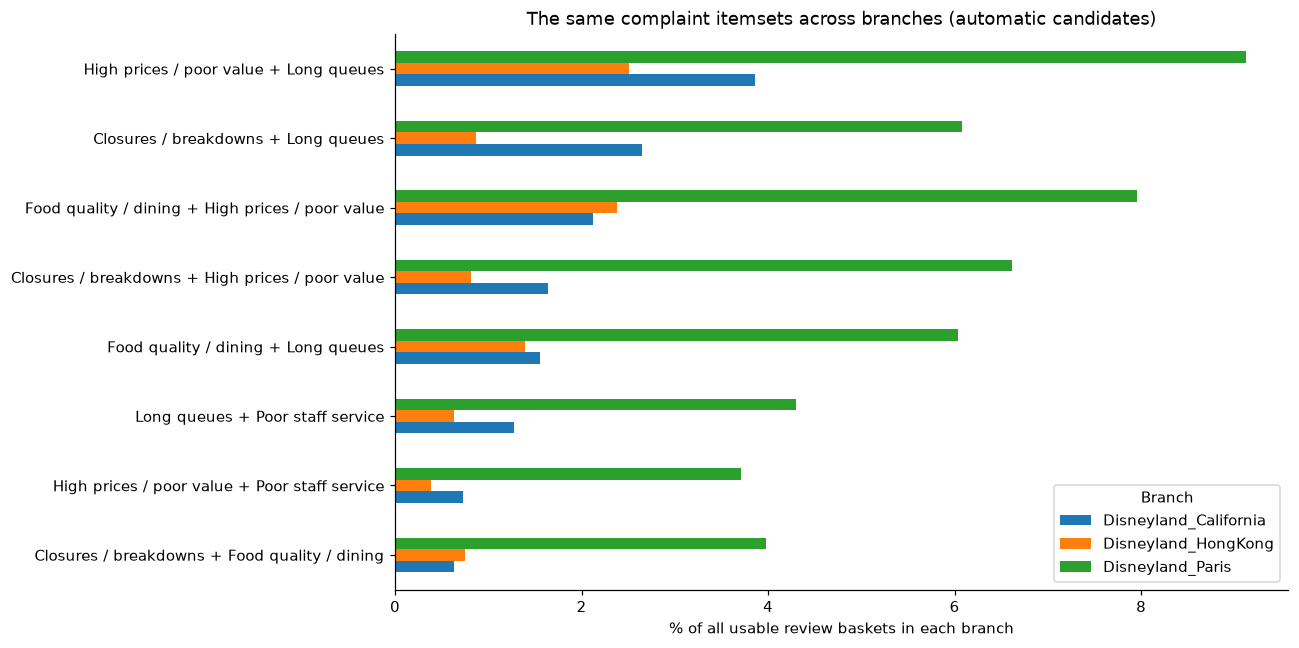

In [29]:
shared_itemsets = sorted(set(frequent_itemsets.loc[frequent_itemsets["size"] >= 2, "itemset"]))
itemset_comparison_rows = []
for itemset in shared_itemsets:
    for branch, baskets in branch_baskets.items():
        count = support_count(baskets, itemset)
        cutoff = max(MIN_REVIEW_COUNT, ceil(MIN_SUPPORT * len(baskets)))
        itemset_comparison_rows.append({"Branch": branch, "itemset": itemset,
            "pattern": " + ".join(itemset), "support_count": count,
            "total_baskets": len(baskets), "support": count / len(baskets),
            "passes_support": count >= cutoff})
itemset_comparison = pd.DataFrame(itemset_comparison_rows, columns=[
    "Branch", "itemset", "pattern", "support_count", "total_baskets", "support", "passes_support"])

rule_keys = sorted(set(zip(selected_rules["antecedent"], selected_rules["consequent"])))
comparison_rows = []
for antecedent, consequent in rule_keys:
    for branch, baskets in branch_baskets.items():
        n = len(baskets)
        joint = support_count(baskets, set(antecedent) | {consequent})
        a_count = support_count(baskets, antecedent)
        b_count = support_count(baskets, {consequent})
        confidence = joint / a_count if a_count else np.nan
        lift = confidence / (b_count / n) if a_count and b_count else np.nan
        cutoff = max(MIN_REVIEW_COUNT, ceil(MIN_SUPPORT * n))
        comparison_rows.append({"Branch": branch, "antecedent": antecedent, "consequent": consequent,
            "rule": " + ".join(antecedent) + " → " + consequent,
            "support_count": joint, "total_baskets": n, "support": joint / n,
            "antecedent_count": a_count, "consequent_count": b_count,
            "confidence": confidence, "lift": lift,
            "passes_all_thresholds": joint >= cutoff and confidence >= MIN_CONFIDENCE and lift >= MIN_LIFT})
rule_comparison = pd.DataFrame(comparison_rows, columns=["Branch", "antecedent", "consequent", "rule",
    "support_count", "total_baskets", "support", "antecedent_count", "consequent_count",
    "confidence", "lift", "passes_all_thresholds"])
display(rule_comparison.head(18).round(3))

if not itemset_comparison.empty:
    support_pivot = itemset_comparison.pivot(index="pattern", columns="Branch", values="support") * 100
    # Same eight patterns on every branch, ranked by their highest observed branch support.
    top_patterns = support_pivot.max(axis=1).nlargest(8).index
    display(support_pivot.loc[top_patterns].round(2))
    support_pivot.loc[top_patterns].sort_values(by=support_pivot.columns[0]).plot.barh(figsize=(12, 6))
    plt.xlabel("% of all usable review baskets in each branch")
    plt.ylabel("")
    plt.title("The same complaint itemsets across branches (automatic candidates)")
    plt.tight_layout()
    plt.show()
else:
    print("No multi-category itemsets passed support. Review thresholds and basket coverage.")

### 9.6 Read evidence for one rule
Use the table above to choose a branch and rule. Below we choose the highest-lift selected rule as a reproducible example, not a recommendation. We retrieve both the matching reviews and their detected complaint segments. Categories may occur in different sentences or concern different services: a review-level basket does not establish a shared attraction, causal connection or sequence.

In [30]:
if not selected_rules.empty:
    chosen = selected_rules.sort_values(["lift", "support_count"], ascending=False).iloc[0]
    needed = set(chosen["antecedent"]) | {chosen["consequent"]}
    matching = fim_reviews.loc[(fim_reviews["Branch"] == chosen["Branch"]) &
                              fim_reviews["basket"].apply(lambda basket: needed.issubset(basket))]
    example_ids = matching.sample(n=min(3, len(matching)), random_state=RANDOM_SEED)["row_id"]
    print("Example rule:", chosen["rule"], "|", chosen["Branch"])
    print(f"Observed in {chosen['support_count']} of {chosen['total_baskets']} usable reviews; "
          f"confidence {chosen['confidence']:.1%}; lift {chosen['lift']:.2f}.")
    display(text_df.loc[text_df["row_id"].isin(example_ids), ["row_id", "rating", "Review_Text"]])
    display(complaints.loc[complaints["row_id"].isin(example_ids) & complaints["category"].isin(needed),
                          ["row_id", "category", "segment", "rule_reason"]])
else:
    print("No rules pass the current cutoffs. There is no top-rule example to inspect.")

Example rule: High prices / poor value + Long queues + Poor staff service → Food quality / dining | Disneyland_Paris
Observed in 144 of 13629 usable reviews; confidence 52.9%; lift 3.88.


,row_id,rating,Review_Text
30550,30561,4,"We visited Disneyland Paris at the end of March, which I had previously researched as being the quietest t..."
38750,38762,1,"For the price you pay to be shoved around by unfriendly staff, queue for hours for every single ride and f..."
41142,41154,2,"Visited half term June 2012, parks are small & few rides. You can easily do both parks in one day if you g..."


,row_id,category,segment,rule_reason
19451,30561,High prices / poor value,"The food is very expensive, which is a shame because less people would bring their own food, if the restau...",explicit_problem_cue
19452,30561,Food quality / dining,"The food is very expensive, which is a shame because less people would bring their own food, if the restau...",negative_segment_plus_topic
19453,30561,Poor staff service,I thought it was exceptionally poor management that other members of staff were not sent to help and anoth...,negative_segment_plus_topic
19454,30561,Long queues,It was also bitterly cold weather for people to wait in the queue.,negative_segment_plus_topic
28942,38762,Long queues,"For the price you pay to be shoved around by unfriendly staff, queue for hours for every single ride and f...",negative_segment_plus_topic
28943,38762,Poor staff service,"For the price you pay to be shoved around by unfriendly staff, queue for hours for every single ride and f...",explicit_problem_cue
28944,38762,High prices / poor value,"For the price you pay to be shoved around by unfriendly staff, queue for hours for every single ride and f...",explicit_problem_cue
28945,38762,Food quality / dining,"For the price you pay to be shoved around by unfriendly staff, queue for hours for every single ride and f...",negative_segment_plus_topic
28946,38762,Long queues,"Restaurant and had to queue for hours, then as soon as queues got shorter they started closing tills so th...",explicit_problem_cue
32384,41154,Poor staff service,Staff unfriendly and miserable (so not the Disney ethos) toilets stink and no atmosphere.,explicit_problem_cue


### 9.7 Check sensitivity to the support threshold
Keep confidence, lift and the count floor fixed; compare support cutoffs of 0.5%, 1% and 2%. More rules at a lower threshold do not mean a better analysis. Review counts, category definitions, language errors and dictionary overlap still determine the quality of the evidence. Branch comparisons are descriptive and can reflect differences in review length, time coverage and reviewer mix.

In [31]:
sensitivity_rows = []
for branch, baskets in branch_baskets.items():
    for support_cutoff in [0.005, 0.01, 0.02]:
        minimum_count = max(MIN_REVIEW_COUNT, ceil(support_cutoff * len(baskets)))
        frequent = apriori_counts(baskets, minimum_count)
        rules = association_rules_from_counts(frequent, len(baskets), MIN_CONFIDENCE)
        sensitivity_rows.append({"Branch": branch, "min_support": support_cutoff,
            "minimum_count": minimum_count,
            "multi_category_itemsets": sum(len(items) >= 2 for items, count in frequent),
            "selected_rules": int((rules["lift"] >= MIN_LIFT).sum())})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

,Branch,min_support,minimum_count,multi_category_itemsets,selected_rules
0,Disneyland_California,0.005,98,19,12
1,Disneyland_California,0.010,195,10,7
2,Disneyland_California,0.020,389,5,3
3,Disneyland_HongKong,0.005,49,12,4
4,Disneyland_HongKong,0.010,97,4,2
5,Disneyland_HongKong,0.020,193,2,1
6,Disneyland_Paris,0.005,69,51,89
7,Disneyland_Paris,0.010,137,32,50
8,Disneyland_Paris,0.020,273,15,23


### 9.8 Export the FIM results
These files join the earlier outputs in this run's folder. `18_fim_baskets.csv` retains every usable-text review, including empty baskets. `19` contains all frequent itemsets, `20` the selected rules, and `21`/`22` the matched cross-branch comparisons. Itemsets and antecedents are JSON arrays when saved. The metadata records all thresholds and the excluded composite category.

After correcting the extraction rules or human labels, rebuild `transactions` and rerun Section 9. The CSV exports do not automatically ingest manual corrections.

In [32]:
fim_export = fim_reviews.copy()
fim_export["basket"] = fim_export["basket"].apply(sorted)
save_table(fim_export, "18_fim_baskets.csv", ["candidate_categories", "basket"])
save_table(frequent_itemsets, "19_frequent_itemsets.csv", ["itemset"])
save_table(selected_rules, "20_selected_association_rules.csv", ["antecedent"])
save_table(itemset_comparison, "21_itemset_branch_comparison.csv", ["itemset"])
save_table(rule_comparison, "22_rule_branch_comparison.csv", ["antecedent"])
save_table(sensitivity, "23_fim_threshold_sensitivity.csv")
save_table(basket_summary.reset_index(), "24_fim_basket_coverage.csv")
metadata["fim"] = {"algorithm": "Apriori; all frequent itemsets; single-consequent rules",
    "min_relative_support": MIN_SUPPORT, "min_review_count": MIN_REVIEW_COUNT,
    "min_confidence": MIN_CONFIDENCE, "min_lift": MIN_LIFT,
    "excluded_categories": sorted(EXCLUDED_FIM_CATEGORIES),
    "denominator": "All usable-text review records per branch, including empty/singleton baskets",
    "basket_rows": len(fim_reviews)}
(run_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Analysis and FIM exports:", run_dir.resolve())

Analysis and FIM exports: C:\Users\jlgel\Downloads\BDCC-Lab1-\outputs\disneyland_analysis\run_20261017_161430_391340


## 10. Write your findings in your own words
Use these prompts after inspecting the outputs:

1. **Data coverage:** “The file contained ___ review records. After removing ___ exact duplicates, ___ remained. ___ had usable text. The largest branch/location groups were ___. ___ dates were unavailable.”
2. **Text exploration:** “BoW showed frequent terms such as ___. TF-IDF highlighted ___. These are text features, not automatic evidence of dissatisfaction.”
3. **Mentions and complaints:** “Our starter rules detected ___; ___% of usable reviews in branch ___ contained a candidate for ___. We counted each review once per category.”
4. **Validation:** “We manually checked ___ examples and found ___. Common errors were ___. Attraction links are tentative because ___.” Do not fill this with claims until you do the checks.
5. **Handoff:** “We prepared one transaction per retained review, with empty category lists preserved and text eligibility recorded. Labels remain candidates pending review.”

**Limitations to discuss:** English vocabulary and sentiment assumptions; uneven branch/location/time coverage; duplicate IDs retained for inspection; incomplete aliases; attraction comparisons across branches; sentence splitting errors; sentiment shared by multiple aspects; negation and sarcasm; overlapping complaint categories; no proof of causation or individual preferences. This baseline does not validate the final recommendation system.

### Troubleshooting
- `FileNotFoundError`: edit `DATA_PATH` or place the CSV beside this notebook; check the printed working folder.
- `ModuleNotFoundError`: uncomment and run the installation cell, restart the kernel and rerun.
- `NameError`: a previous cell was skipped; restart and run from the top.
- `empty vocabulary`: inspect `clean_text`; for a very small custom sample, lower `min_df` to 1 and set `max_df=1.0` in both vectorizers.
- Slow sentiment cell: allow several minutes for the full file. Do not interrupt and then use partially built tables.
- No match: an empty alias list is not proof the attraction or complaint is absent. Inspect the text and expand the dictionaries.

### References and adaptation notes
- Supplied `information-retrieval.ipynb`, section **1 Data Preparation**, and its `[adlib]` version: CountVectorizer teaching sequence. Original notebook credits Prof Christian Alis, revised and edited by Leodegario Lorenzo II. The code here is written for your Disneyland task.
- Supplied `07-information-retrieval.pdf`, slides 15–17: text preparation, BoW and TF-IDF concepts.
- Supplied `GamePLan+LT+1B.+ver+5pdf.pdf`, page 1: branch/location coverage, phrase matching, sentiment and downstream complaint transactions. This workbook now also implements complaint-basket FIM and branch comparisons.
- [scikit-learn text feature extraction guide](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction): vectorization, sparse matrices and TF-IDF implementation details.
- [VADER official repository and documentation](https://github.com/cjhutto/vaderSentiment): scoring and sentiment thresholds. VADER is a baseline, not a validation of these Disneyland labels.

**FIM write-up prompt:** “Using ___ usable text reviews in branch ___, the itemset ___ appeared in ___ reviews (___% support). For the rule ___ → ___, confidence was ___% and lift was ___. In another branch, the same rule had ___. Thresholds were ___. These are descriptive associations among automatically extracted complaint candidates, not evidence that one problem causes another.”

**FIM reference:** `Frequent Itemset Mining (3).ipynb`, prepared by Christian Alis: transaction sets, absolute/relative support, Apriori and association rules. We use clear Python functions rather than requiring pyFIM. Unlike the retail example's filtering step, we retain empty and singleton baskets so our denominator remains all usable review records. Apriori is sufficient for this small category vocabulary; an FP-growth implementation is not needed for this task.
